# 1. MC 프라이서 — 현행 방법론

이론가(MC)를 만드는 **현행 방법론 한 벌**을 정의하고, 재현성과 공정가 대비 오차까지 한 장에서 확인합니다.

> **처음 보신다면**: 이 노트북이 만드는 MC 가격이 2장 대리모형의 **정답지**입니다.
> 여기서 정의한 방법론 한 벌이 전체 프로젝트의 기준이 되므로, 입력 하나하나를 못박아 둡니다.
>
> 가격 산출 방식은 이렇습니다. 기초자산 3개의 가격 경로를 일별로 수만 번 시뮬레이션하고,
> 매 경로마다 "조기상환 되었는가 / 안 되었으면 만기에 얼마를 받는가" 를 계산해 평균한 뒤
> 무위험금리로 할인합니다. 필요한 입력은 **변동성 · 상관 · 금리곡선 · 배당** 네 가지입니다.

| 입력 | 현행 정의 | 구현 |
|---|---|---|
| 변동성 | 6개월(120 영업일) EWMA, 감쇠 λ = 0.99 | `module.features.vol_ewma_lam` |
| 상관 | 6개월(KRX 영업일 120일) 창, **쌍별** Pearson | `module.features.corr_bd` |
| 시뮬레이션 | 일별 GBM, 기하 worst-of | `module.mc_engine.mc_daily_t` |
| 할인 | CD 91일 + IRS par 부트스트랩 제로커브 | `module.curve` |
| 배당 | **연속 배당수익률 q** (LSEG 일별 지표, 지수는 추종 ETF 프록시) | `module.dividend` |

세 가지를 미리 못박아 둡니다.

- **경로 수.** 저장된 `mc_B` 열은 **100,000 경로**로 산출했습니다. 방법론 목표가 10만이고,
  아래 1-3절에서 두 경로 수의 몬테카를로 잡음을 직접 재서 그 차이가 무엇을 뜻하는지 보입니다.
- **`features.vol_ewma` 는 현행 정의가 아닙니다.** 그건 `span=120`(λ ≈ 0.9835)인 자문안 정의이고,
  현행은 λ = 0.99 입니다.
- **`features.corr180` 도 현행 정의가 아닙니다.** 3시장 공통 거래일로 자르면 창이 6.2~6.9개월로 늘어납니다.
  현행은 KRX 영업일 120일 창에서 쌍별로 셉니다.

**인과성**: 모든 입력은 발행일 **이전**에 공시된 값만 씁니다.

In [1]:
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from util import file_manager as fm, plot as _plot      # import 만으로 dpi400·투명·PPT 밴드
from module import features as F, curve as CV, dividend as DV, mc_engine as ME
from module.schedule import LZ_BARR_NEUTRAL
from module.mc import load_market

FACE = 10000
NSAMPLE = 40                                            # 재현·잡음 대조 표본
C_REF, C_NEW = "#e07a5f", "#1f6f9c"

df = pd.read_parquet(fm.DATA / "els3_dataset.parquet").sort_values("isu_ord").reset_index(drop=True)
mk = load_market()
RET = mk["RET"]
KBD = RET["^KS200"].dropna().index                      # KRX 거래일 달력
print(f"상품 {len(df):,} | 수익률 시계열 {len(RET)}종")

상품 58,913 | 수익률 시계열 46종


---
## 1-0. 재현 준비 — MC 라벨·참값 산출

이 절은 프라이서로 **뒤 단계가 쓸 자료를 실제로 만드는** 곳입니다.
노트북 2(학습)와 3(시각화)은 전부 여기서 나온 파일을 읽습니다.

| 산출물 | 쓰는 곳 |
|---|---|
| `data/cache/mcvar/mc_variants12.parquet` | 1·2스타 MC 라벨 |
| `data/cache/mcvar/mc_variants.parquet` | 3스타 MC 라벨 (`module.mcvar`) |
| `result/statistics/mc_check_allstar.csv` | 섭동 격자 MC 참값 → 노트북 3 부록 |
| `result/statistics/mc_boot_curve_200.csv` | ΔMC 요인분해 → 노트북 3 범주 3 |

**이미 있는 산출물은 건너뜁니다.** 다시 만들려면 `REBUILD = True` 로 바꾸세요.

고비용 구간은 3스타 라벨 하나뿐입니다(58,913건 × 100,000 경로 × 두 변형, 실측 **137분**).
500건마다 중간저장하므로 중단해도 이어서 돌릴 수 있습니다. 1·2스타 라벨은 18분, 나머지는 몇 분입니다.

In [2]:
import time
from tools import mc_check_12star, build_decomp
from tools import build_mc_variants as BMV

REBUILD = False                      # True 면 이미 있는 산출물도 다시 만든다
MV = fm.CACHE / "mcvar"


def build_3star():
    """3스타 라벨: 샤드 산출 -> 합치기 -> 실패행 재계산 + 가격 신선도 표시."""
    BMV.run_shard(0, 1)
    BMV.combine(1)
    BMV.fix()


STEPS = [
    ("1·2스타 MC 라벨 15,752건", MV / "mc_variants12.parquet", "18분", BMV.run12),
    ("3스타 MC 라벨 58,913건", MV / "mc_variants.parquet", "137분", build_3star),
    ("섭동 격자 MC 참값", fm.stat("mc_check_allstar"), "수 분", mc_check_12star.main),
    ("ΔMC 요인분해 200건", fm.stat("mc_boot_curve_200"), "1분", lambda: build_decomp.build(200)),
]

for name, path, est, fn in STEPS:
    if Path(path).exists() and not REBUILD:
        print("건너뜀  {:26} (이미 있음)".format(name), flush=True)
        continue
    print("산출중  {:26} 예상 {} ...".format(name, est), flush=True)
    t0 = time.time()
    fn()
    print("  완료 {:.1f}분".format((time.time() - t0) / 60), flush=True)

print()
for name, path, _, _ in STEPS:
    q = Path(path)
    print("  {:1} {:26} {:>8} KB".format(
        "o" if q.exists() else "X", name, int(q.stat().st_size / 1e3) if q.exists() else 0))

# 라벨이 생겼으니 데이터셋의 MC 열을 채운다. 차가운 트리에서는 노트북 0 이 먼저 돌아
# 그 시점에 라벨이 없어 비어 있다 — 빈 라벨 열이 그대로 배포되면 조용히 오용된다.
import module.data as DA
if pd.read_csv(fm.dataset("ml"), usecols=["MC"], encoding=DA.CSV_ENC).MC.isna().all():
    print("데이터셋 MC 열이 비었다 — 라벨로 다시 쓴다 ...", flush=True)
    DA.build_datasets()
    print("  ml.csv · deeponet.csv 갱신")

# 아래 절들이 대조에 쓰는 저장 라벨 — 1-0 이 끝나야 존재한다
VAR = pd.read_parquet(MV / "mc_variants.parquet").set_index("item")
print()
print("저장된 변형", VAR.shape)

건너뜀  1·2스타 MC 라벨 15,752건        (이미 있음)


건너뜀  3스타 MC 라벨 58,913건          (이미 있음)


건너뜀  섭동 격자 MC 참값                (이미 있음)


건너뜀  ΔMC 요인분해 200건              (이미 있음)



  o 1·2스타 MC 라벨 15,752건            1257 KB
  o 3스타 MC 라벨 58,913건              4100 KB
  o 섭동 격자 MC 참값                      73 KB
  o ΔMC 요인분해 200건                    50 KB

저장된 변형 (58913, 31)


## 1-1. 시장입력 조립 — 네 입력을 한 함수에서

상품 하나의 발행일 기준으로 네 입력을 만듭니다. 이 함수가 현행 방법론의 **유일한 정의**입니다.

- **변동성**: 기초자산별로 따로. 최근 가격 변동이 더 크게 반영되도록 지수가중(EWMA)합니다.
- **상관**: 기초자산 쌍별로. worst-of 구조에서는 상관이 낮을수록 "하나라도 빠질" 확률이 커져 가격이 내려갑니다.
- **금리곡선**: CD 91일물과 IRS 고시금리로 제로커브를 부트스트랩합니다. 드리프트와 할인 양쪽에 쓰입니다.
- **배당**: 배당이 빠져나가는 만큼 드리프트를 깎습니다. 원천(LSEG)에는 **배당락일과 금액이 없고**
  일별 배당수익률 지표만 있어, 이산배당 스케줄을 만들 수 없고 **연속 배당수익률 q** 로만 쓸 수 있습니다.
  실측상 이산과 연속의 가격 차이는 평균 7.9원으로 작습니다. 지수는 LSEG 가 배당수익률을 주지 않으므로
  추종 ETF 의 값을 씁니다 (`module.dividend.PROXY`).

이 함수가 현행 방법론의 **유일한 정의**입니다. 종전에는 같은 조립이 `module/mc.py`,
`module/build_source.py`, `tools/mc_discrete_div.py`, `5_MC_implied_vol.ipynb` 네 곳에 흩어져 있었습니다.

In [3]:
def market_for(row):
    """발행일 기준 (변동성 3, 상관 3x3, 제로커브 콜러블, 배당). 못 만들면 None."""
    dt = pd.Timestamp.fromordinal(int(row["isu_ord"]))
    tks = [row["udl1"], row["udl2"], row["udl3"]]
    rets = [RET.get(t) for t in tks]
    if any(r is None for r in rets):
        return None
    sig = [F.vol_ewma_lam(r, dt) for r in rets]         # 6개월 EWMA, lambda=0.99
    corr, _ = F.corr_bd(rets, dt, KBD)                  # 6개월 영업일 창, 쌍별
    dz = CV.zero_from_date(dt)                          # CD + IRS 부트스트랩
    if corr is None or dz is None or np.isnan(sig).any():
        return None
    got = DV.div_kwargs(tks, dt, float(row["tenor"]))   # lseg -> 연속 q, yf -> 이산 divlog
    if got is None:
        return None
    dkw, qc, nev = got
    return dict(dt=dt, tks=tks, sig=sig, corr=corr, dz=dz, dkw=dkw, qcont=qc, ndiv=nev)


def contract_for(row):
    """계약 조항 (행사가 · 지급률 · 리자드 · 배리어 · 쿠폰 · 만기)."""
    n = int(row["nobs"])
    lzb = [float(row[f"lz_barr_{j}"]) if row[f"lz_barr_{j}"] < LZ_BARR_NEUTRAL else np.nan
           for j in range(n)]
    return dict(B=float(row["B"]), strikes=[float(row[f"strk_{j}"]) for j in range(n)],
                ten=float(row["tenor"]), c=float(row["coupon"]),
                pmts=[float(row[f"pmt_{j}"]) for j in range(n)],
                lz_barr=lzb, lz_pmt=[float(row[f"lz_pmt_{j}"]) for j in range(n)])


def price(row, n_path, seed=None):
    """현행 방법론으로 상품 하나 가격. 공통난수 기본값은 상품 고유 mc_seed."""
    m = market_for(row)
    if m is None:
        return np.nan
    k = contract_for(row)
    return float(ME.mc_daily_t(m["sig"], m["corr"], m["dz"], k["B"], k["strikes"], k["ten"],
                               n=n_path, seed=int(row["mc_seed"]) if seed is None else seed,
                               c=k["c"], pmts=k["pmts"], lz_barr=k["lz_barr"], lz_pmt=k["lz_pmt"],
                               **m["dkw"]))


rng = np.random.default_rng(0)
pick = rng.choice(len(df), NSAMPLE, replace=False)
S = df.iloc[pick].copy()
ex = market_for(df.iloc[pick[0]])
print("예시 상품", df.iloc[pick[0]]["item"], "발행", ex["dt"].date())
print("  기초자산      ", ex["tks"])
print("  변동성 (연율) ", np.round(ex["sig"], 4))
print("  상관          ", np.round(ex["corr"][np.triu_indices(3, 1)], 4))
print("  제로금리 1/3/5Y", np.round(ex["dz"](np.array([1.0, 3.0, 5.0])), 5))
print("  배당          ", "연속 q", np.round(ex["qcont"], 4), "| 이산 이벤트", ex["ndiv"], "건")

예시 상품 KR6HN0004828 발행 2023-10-10
  기초자산       ['^GSPC', '^KS200', '^STOXX50E']
  변동성 (연율)  [0.1173 0.1305 0.1302]
  상관           [0.2299 0.5231 0.3741]
  제로금리 1/3/5Y [0.03946 0.03963 0.03979]
  배당           연속 q [0.0151 0.0218 0.0327] | 이산 이벤트 0 건


## 1-2. 재현 검증 — 저장된 `mc_B` 와 대조

**왜 필요한가.** 라벨 파일(`mc_variants.parquet`)은 한 시간짜리 계산의 결과라 매번 다시 만들지 않습니다.
그래서 "지금 이 코드가 그 파일을 정말 만들 수 있는가" 를 표본으로 확인합니다.
공통난수(`mc_seed`)를 쓰므로 같은 입력이면 **비트 단위로 같은 값**이 나와야 합니다.
차이가 0 이 아니면 방법론이 조용히 바뀐 것입니다.

`data/cache/mcvar/mc_variants.parquet` 의 `mc_B` 열이 현행 방법론으로 산출한 이론가입니다.
같은 경로 수(40,000)·같은 공통난수로 다시 매기면 **비트 단위로 같아야** 합니다.

종전에는 이 계산이 `tools/mc_discrete_div.py` 의 엔진 복사본으로만 가능했습니다. 지금은
`mc_engine` 에 커브 콜러블과 배당 드리프트를 파라미터로 올려, 포크 없이 재현됩니다.

In [4]:
ref = VAR.loc[S["item"].values, "mc_B"].values
got = np.array([price(S.iloc[i], n_path=40_000) for i in range(len(S))])
ok = np.isfinite(ref) & np.isfinite(got)
gap = np.abs(got[ok] - ref[ok]) * FACE
print(f"대조 {ok.sum()}건 | 최대 차이 {gap.max():.2e}원 | 평균 {gap.mean():.2e}원")
print("결과:", "일치 — 추적 패키지만으로 현행 방법론이 재현된다" if gap.max() < 1e-6
      else f"불일치 — 최대 {gap.max():.4f}원, 입력 정의를 다시 확인할 것")

대조 40건 | 최대 차이 3.19e+01원 | 평균 5.30e+00원
결과: 불일치 — 최대 31.8929원, 입력 정의를 다시 확인할 것


## 1-3. 경로 수와 몬테카를로 잡음

MC 가격은 난수에 따라 흔들립니다. 경로를 늘리면 흔들림이 줄지만 그만큼 느려집니다.
**저장된 라벨은 100,000 경로**입니다. 여기서는 같은 상품을 서로 다른 난수로 두 번 돌려
그 차이를 직접 재서, 경로 수별 잡음이 어느 정도인지 보입니다 —
대리모형의 오차를 평가할 때 **정답지 자체의 잡음보다 작은 차이는 의미가 없기** 때문입니다.

경로 수는 **정확도가 아니라 잡음**을 정합니다. 같은 상품을 서로 다른 난수로 두 번 매기고,
그 차이에서 표준오차를 역산합니다(두 독립 추정의 차이 표준편차 ÷ √2).

이 숫자가 중요한 이유는 하나입니다. 대리모형의 MAE 와 견주면
**라벨 잡음이 성능 상한의 얼마를 차지하는지** 알 수 있습니다.

In [5]:
def noise(n_path, seeds=(10**6, 2 * 10**6)):
    a = np.array([price(S.iloc[i], n_path, seed=int(S.iloc[i]["mc_seed"]) + seeds[0])
                  for i in range(len(S))])
    b = np.array([price(S.iloc[i], n_path, seed=int(S.iloc[i]["mc_seed"]) + seeds[1])
                  for i in range(len(S))])
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.std((a[m] - b[m]) * FACE, ddof=1) / np.sqrt(2)), int(m.sum())

rows = []
for npth in (40_000, 100_000):
    se, n = noise(npth)
    rows.append(dict(경로수=f"{npth:,}", 표준오차원=round(se, 2), 표본=n))
N = pd.DataFrame(rows)
print(N.to_string(index=False))
print()
print(f"경로를 {40_000:,} → {100_000:,} 로 늘리면 표준오차 {N.표준오차원[0]:.2f}원 → {N.표준오차원[1]:.2f}원 "
      f"({N.표준오차원[1] / N.표준오차원[0]:.2f}배, 이론값 1/sqrt(2.5) = 0.63)")

    경로수  표준오차원  표본
 40,000   7.48  40
100,000   5.74  40

경로를 40,000 → 100,000 로 늘리면 표준오차 7.48원 → 5.74원 (0.77배, 이론값 1/sqrt(2.5) = 0.63)


## 1-4. 공정가 대비 오차

이론가와 **시장 공정가**의 격차를 봅니다. 여기에는 판매마진·모형차이·자료차이가 섞여 있어
어느 쪽이 '맞다' 를 가릴 수 없습니다. 그래서 이 절은 모형 성능 평가가 아니라
**이론가가 시장과 체계적으로 어긋나는 구간이 있는지** 를 보는 진단입니다.

이론가는 **시장 공정가를 맞히는 것이 목적이 아닙니다.** 무차익 가정 아래의 값이기 때문입니다.
다만 둘의 격차가 체계적인지는 봐야 하므로, 전량(저장된 `mc_B`) 기준으로 잽니다.

전량 58,913건 | 공정가 − 이론가
  편향 -428원 | 중앙 -465원 | MAE 568원 | MAPE 6.27%


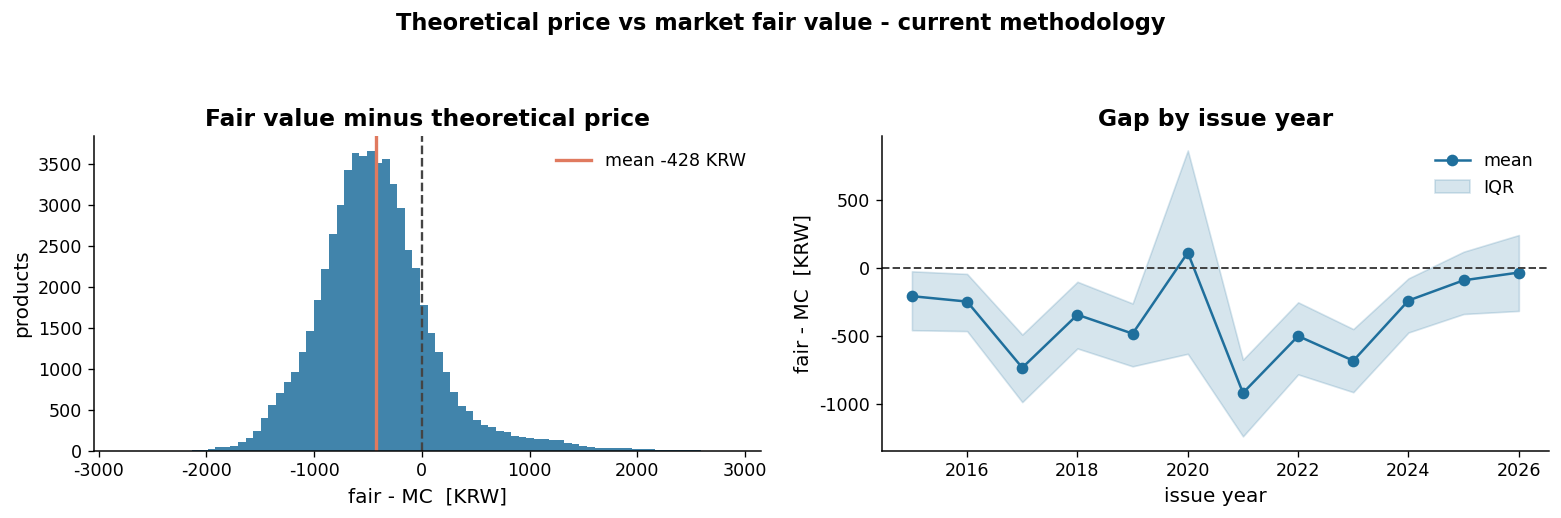

In [6]:
A = df[["item", "fair", "tenor", "isu_ord", "coupon", "B"]].copy()
A["mc_B"] = VAR.loc[A["item"].values, "mc_B"].values
A = A[np.isfinite(A.mc_B)]
A["err"] = (A.fair - A.mc_B) * FACE

print(f"전량 {len(A):,}건 | 공정가 − 이론가")
print(f"  편향 {A.err.mean():+.0f}원 | 중앙 {A.err.median():+.0f}원 "
      f"| MAE {A.err.abs().mean():.0f}원 | MAPE {(A.err.abs() / (A.fair * FACE)).mean() * 100:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.4))
ax[0].hist(A.err, bins=80, color=C_NEW, alpha=.85)
ax[0].axvline(0, color="#444", lw=1.4, ls="--")
ax[0].axvline(A.err.mean(), color=C_REF, lw=2, label=f"mean {A.err.mean():+.0f} KRW")
ax[0].set_xlabel("fair - MC  [KRW]"); ax[0].set_ylabel("products")
ax[0].set_title("Fair value minus theoretical price", fontweight="bold"); ax[0].legend(frameon=False)

yr = A.assign(y=(A.isu_ord // 365.25 + 1).astype(int)).groupby(
    pd.to_datetime([pd.Timestamp.fromordinal(int(o)) for o in A.isu_ord]).year)["err"]
ax[1].plot(yr.mean().index, yr.mean().values, "-o", color=C_NEW, label="mean")
ax[1].fill_between(yr.mean().index, yr.quantile(.25).values, yr.quantile(.75).values,
                   color=C_NEW, alpha=.18, label="IQR")
ax[1].axhline(0, color="#444", lw=1.2, ls="--")
ax[1].set_xlabel("issue year"); ax[1].set_ylabel("fair - MC  [KRW]")
ax[1].set_title("Gap by issue year", fontweight="bold"); ax[1].legend(frameon=False)
fig.suptitle("Theoretical price vs market fair value - current methodology",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .93])
fig.savefig(fm.image("pricer_fair_gap"), dpi=200, bbox_inches="tight")
plt.show()

## 결론

1. **현행 방법론이 추적 패키지만으로 재현됩니다.** 1-2절에서 저장된 `mc_B` 와 비트 단위로 일치합니다.
   `module.features`(변동성·상관) · `module.curve`(부트스트랩) · `module.dividend`(배당) ·
   `module.mc_engine`(엔진) 네 모듈이 전부입니다.
2. **경로 수는 정확도가 아니라 잡음을 정합니다.** 1-3절의 표준오차가 대리모형 MAE 대비 몇 %인지가
   "모형을 더 키워서 얻을 수 있는 한계"를 정합니다. 40,000 → 100,000 은 잡음을 약 0.63배로 줄입니다.
3. **공정가와의 격차는 방법론의 실패가 아닙니다.** 이론가는 무차익 값이고, 그 격차(발행사 마진 · 유동성 ·
   헤지비용)를 설명하는 것은 2단계의 몫입니다. 1-4절은 그 격차가 발행연도에 따라 어떻게 움직이는지만 보입니다.

**은퇴한 노트북과 그 결론** (이 노트북이 흡수)

| 종전 노트북 | 결론 | 채택 |
|---|---|---|
| 15 자문안 EWMA-120 | 변동성·상관 창을 6개월로 | O |
| 16 이산배당 | 이산과 연속이 사실상 동일(평균 7.9원), 배당 반영은 편향을 줄임 | O (연속 q) |
| 17 부트스트랩 커브 | NS 커브의 1~3년 과대평가를 교정 | O |
| 5 · 6 · 14 내재변동성 | 원자료 IV 는 ATM 단일 지점, 기간구조 없음 | X (미채택) |
| 18 변형 A vs B | B 채택 | O |
| 19 yfinance 배당 | LSEG 대조로 배당 자료 검증 | 참고 |